# Superstore Data Cleaning

In [1]:
from pathlib import Path
import pandas as pd

source_candidates = [
    Path("data/sample-superstore.xls"),
    Path("../data/sample-superstore.xls"),
]
source_path = next((path for path in source_candidates if path.exists()), None)
if source_path is None:
    raise FileNotFoundError("Could not find data/sample-superstore.xls")

df = pd.read_excel(source_path, engine="xlrd")
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns from {source_path}")

Loaded 10,194 rows and 21 columns from ..\data\sample-superstore.xls


In [2]:
rows_before_cleaning = len(df)
duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

date_columns = [column for column in ["Order Date", "Ship Date"] if column in df.columns]
for column in date_columns:
    df[column] = pd.to_datetime(df[column], errors="coerce")

rows_before_date_drop = len(df)
if date_columns:
    df = df.dropna(subset=date_columns).copy()
date_rows_dropped = rows_before_date_drop - len(df)

if "Postal Code" in df.columns:
    df["Postal Code"] = df["Postal Code"].astype("string")

missing_before = int(df.isna().sum().sum())
for column in df.select_dtypes(include="number").columns:
    median = df[column].median()
    df[column] = df[column].fillna(median if pd.notna(median) else 0)

text_columns = df.select_dtypes(include=["object", "string", "category"]).columns
for column in text_columns:
    if df[column].isna().any():
        mode = df[column].mode(dropna=True)
        df[column] = df[column].fillna(mode.iloc[0] if not mode.empty else "Unknown")

if "Quantity" in df.columns:
    df["Quantity"] = df["Quantity"].round().astype("int64")

categorical_columns = [
    "Ship Mode", "Segment", "Country/Region", "Region", "Category", "Sub-Category"
]
for column in categorical_columns:
    if column in df.columns:
        df[column] = df[column].astype("category")

print(f"Exact duplicate rows removed: {duplicates_removed}")
print(f"Rows dropped for missing or invalid dates: {date_rows_dropped}")
print(f"Missing values before filling: {missing_before}")
print(f"Missing values after filling: {int(df.isna().sum().sum())}")

Exact duplicate rows removed: 0
Rows dropped for missing or invalid dates: 0
Missing values before filling: 0
Missing values after filling: 0


In [3]:
numeric_columns = [
    column for column in df.select_dtypes(include="number").columns
    if column != "Row ID"
]
outlier_summary = {}

for column in numeric_columns:
    original_dtype = df[column].dtype
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = int(((df[column] < lower_bound) | (df[column] > upper_bound)).sum())
    df[column] = df[column].clip(lower=lower_bound, upper=upper_bound)
    if pd.api.types.is_integer_dtype(original_dtype):
        df[column] = df[column].astype(original_dtype)
    outlier_summary[column] = {
        "outliers_clipped": outlier_count,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
    }

pd.DataFrame.from_dict(outlier_summary, orient="index")

,outliers_clipped,lower_bound,upper_bound
Sales,1183,-271.200000,497.920000
Quantity,175,-2.500000,9.500000
Discount,874,-0.300000,0.500000
Profit,1913,-39.544887,70.603612


In [4]:
print(f"Rows before cleaning: {rows_before_cleaning:,}")
print(f"Cleaned dataset shape: {df.shape}")
print("Remaining missing values:", int(df.isna().sum().sum()))
print("Column data types:")
print(df.dtypes.to_string())
df.head()

Rows before cleaning: 10,194
Cleaned dataset shape: (10194, 21)
Remaining missing values: 0
Column data types:
Row ID                     int64
Order ID                     str
Order Date        datetime64[us]
Ship Date         datetime64[us]
Ship Mode               category
Customer ID                  str
Customer Name                str
Segment                 category
Country/Region          category
City                         str
State/Province               str
Postal Code               string
Region                  category
Product ID                   str
Category                category
Sub-Category            category
Product Name                 str
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.551200
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.5,-5.487000
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.271700
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-39.544887
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.884000


In [5]:
cleaned_path = source_path.with_name("sample-superstore-cleaned.csv")
df.to_csv(cleaned_path, index=False)
print(f"Cleaned dataset saved to: {cleaned_path.resolve()}")

Cleaned dataset saved to: C:\Users\syed1\Desktop\Data Analytics\apexplanet-data-analytics\data\sample-superstore-cleaned.csv


## Statistical Summary

In [6]:
print("DataFrame information:")
df.info()
print("\nStatistical summary:")
df.describe(include="all").T

DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  category      
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  category      
 8   Country/Region  10194 non-null  category      
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  string        
 12  Region          10194 non-null  category      
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  category  

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Row ID,10194.0,NaN,NaN,NaN,5097.5,1.0,2549.25,5097.5,7645.75,10194.0,2942.898656
Order ID,10194,5111,US-2026-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,10194,NaN,NaN,NaN,2025-04-29 11:48:25.002943,2023-01-03 00:00:00,2024-05-14 00:00:00,2025-06-25 00:00:00,2026-05-14 00:00:00,2026-12-30 00:00:00,NaN
Ship Date,10194,NaN,NaN,NaN,2025-05-03 10:52:45.626839,2023-01-07 00:00:00,2024-05-19 00:00:00,2025-06-28 00:00:00,2026-05-18 00:00:00,2027-01-05 00:00:00,NaN
Ship Mode,10194,4,Standard Class,6120,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,10194,804,WB-21850,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,10194,800,William Brown,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,10194,3,Consumer,5281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country/Region,10194,2,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,10194,542,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Distributions

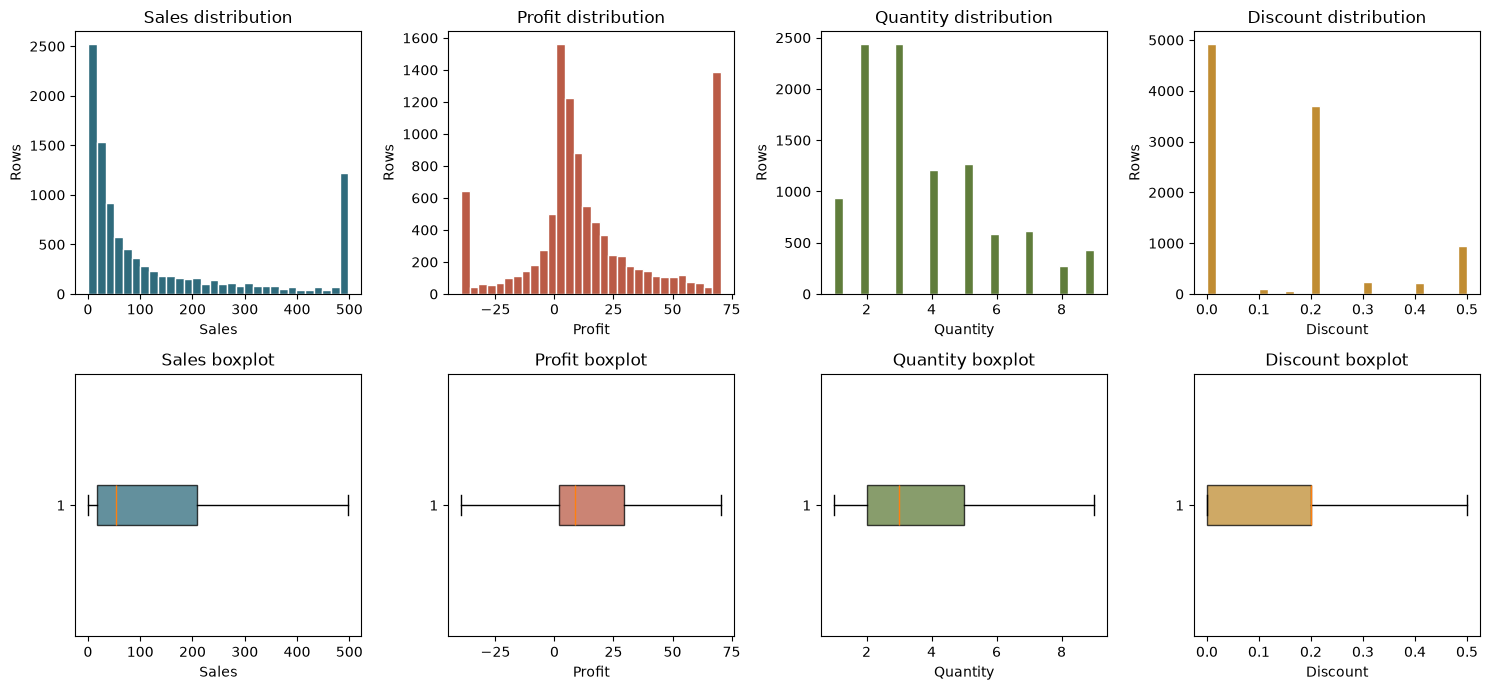

In [7]:
import matplotlib.pyplot as plt

measure_columns = ["Sales", "Profit", "Quantity", "Discount"]
plot_colors = ["#2f6b7c", "#ba5b46", "#607d3b", "#c08c32"]
fig, axes = plt.subplots(2, len(measure_columns), figsize=(15, 7))

for index, column in enumerate(measure_columns):
    values = df[column].dropna()
    axes[0, index].hist(values, bins=30, color=plot_colors[index], edgecolor="white")
    axes[0, index].set_title(f"{column} distribution")
    axes[0, index].set_xlabel(column)
    axes[0, index].set_ylabel("Rows")
    axes[1, index].boxplot(
        values,
        orientation="horizontal",
        patch_artist=True,
        boxprops={"facecolor": plot_colors[index], "alpha": 0.75},
    )
    axes[1, index].set_title(f"{column} boxplot")
    axes[1, index].set_xlabel(column)

fig.tight_layout()
plt.show()

## Categorical Comparisons

In [ ]:
category_totals = (
    df.groupby("Category", observed=True)[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
)
region_sales = df.groupby("Region", observed=True)["Sales"].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].bar(category_totals.index.astype(str), category_totals["Sales"], color="#2f6b7c")
axes[0].set_title("Sales by category")
axes[0].set_ylabel("Sales ($)")
axes[1].bar(category_totals.index.astype(str), category_totals["Profit"], color="#ba5b46")
axes[1].set_title("Profit by category")
axes[1].set_ylabel("Profit ($)")
axes[2].bar(region_sales.index.astype(str), region_sales.values, color="#607d3b")
axes[2].set_title("Sales by region")
axes[2].set_ylabel("Sales ($)")

for axis in axes:
    axis.tick_params(axis="x", labelrotation=35)
    axis.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

![Sales and profit by category, plus sales by region](../data/superstore_categorical_comparison.png)

## Correlation Heatmap

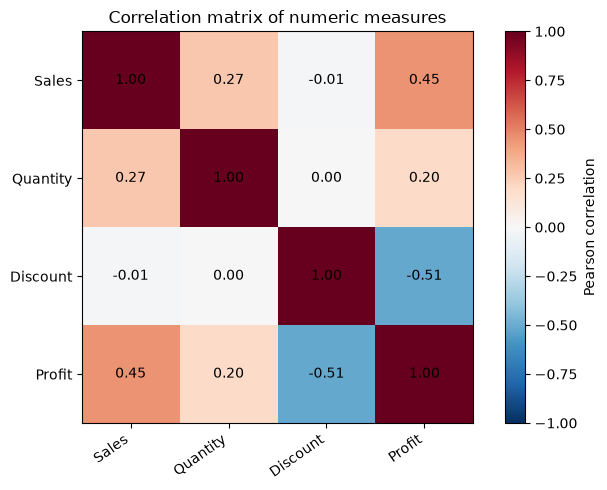

In [9]:
correlation_matrix = (
    df.select_dtypes(include="number")
    .drop(columns=["Row ID"], errors="ignore")
    .corr()
)
fig, axis = plt.subplots(figsize=(7, 5))
image = axis.imshow(correlation_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
axis.set_xticks(range(len(correlation_matrix.columns)))
axis.set_xticklabels(correlation_matrix.columns, rotation=35, ha="right")
axis.set_yticks(range(len(correlation_matrix.index)))
axis.set_yticklabels(correlation_matrix.index)
axis.set_title("Correlation matrix of numeric measures")

for row in range(len(correlation_matrix.index)):
    for column in range(len(correlation_matrix.columns)):
        axis.text(
            column,
            row,
            f"{correlation_matrix.iloc[row, column]:.2f}",
            ha="center",
            va="center",
            color="black",
        )

fig.colorbar(image, ax=axis, label="Pearson correlation")
fig.tight_layout()
plt.show()

## Sales Trend Over Time

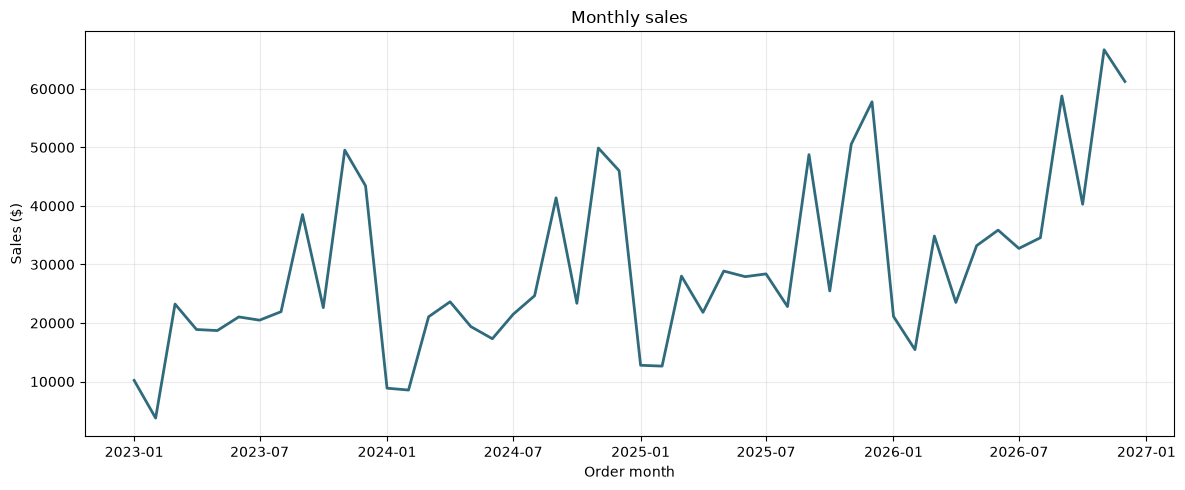

In [10]:
monthly_sales = (
    df.set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
)
fig, axis = plt.subplots(figsize=(12, 5))
axis.plot(monthly_sales.index, monthly_sales.values, color="#2f6b7c", linewidth=2)
axis.set_title("Monthly sales")
axis.set_xlabel("Order month")
axis.set_ylabel("Sales ($)")
axis.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Five Key Insights

The dollar totals below describe the cleaned data after IQR clipping.

1. Office Supplies leads category sales at $500,550.84 and category profit at $82,909.08.
2. Furniture sales ($490,876.37) are close to Office Supplies sales, but Furniture profit is lower at $25,465.92.
3. The West has the highest regional sales ($469,976.51); the South has the lowest ($228,159.16).
4. Consumer is the largest customer segment by sales ($727,388.91), compared with $258,985.83 for Home Office.
5. Monthly sales peak in November 2026 ($66,673.82). Discount and profit have a negative correlation (-0.514); this association does not establish causation.